In [46]:
# loading libraries
import pyfesom2 as pf
import matplotlib.pylab as plt
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.tri as mtri
import matplotlib.path as mpath
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import time
import dask.array as da
from scipy.spatial import cKDTree
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors


In [6]:
# loading mesh
meshpath = '/albedo/work/projects/p_trr181/ebagaeva/work/ebagaeva/3IGW/Meshes/farc/'
alpha, beta, gamma=[0, 0, 0]
mesh=pf.load_mesh(meshpath, abg=[alpha, beta, gamma], usepickle = False, usejoblib=True)

The usejoblib == True)
The joblib file for FESOM2 exists.
The mesh will be loaded from /albedo/work/projects/p_trr181/ebagaeva/work/ebagaeva/3IGW/Meshes/farc/joblib_mesh_fesom2


In [28]:
#loading SSH data
data_path= '/albedo/work/projects/p_trr181/ebagaeva/work/ebagaeva/3IGW/JRA55_2014/Tides_march_2try/'

ssh = pf.get_data(data_path,
                   "ssh", 
                   2014,
                   mesh,
                   how='ori',
                   compute=False, 
                  chunks={'nod2':10000, 'nz1':5})

print (ssh.shape)

Depth is None, 3d field will be returned
(504, 638387)


/albedo/soft/sw/conda-sw/analysis-toolbox-python-04.2026/lib/python3.12/site-packages/pyfesom2/load_mesh_data.py:469: UserWarning: The specified chunks separate the stored chunks along dimension "nod2" starting at index 10000. This could degrade performance. Instead, consider rechunking after loading.
  dataset = xr.open_mfdataset(paths, combine="by_coords", **kwargs)


In [29]:
# to check the repetitions
# Extract timestamps
times = pd.DatetimeIndex(ssh.time.values)

# Find duplicates
duplicates = times[times.duplicated(keep=False)]

print(f"Total timestamps:  {len(times)}")
print(f"Unique timestamps: {times.nunique()}")
print(f"Duplicate entries: {len(times) - times.nunique()}")

if len(duplicates) > 0:
    print("\nRepeated timestamps and their counts:")
    print(pd.Series(duplicates).value_counts().sort_index())
else:
    print("\nNo duplicate timestamps found!")

# Check time range
print(f"\nFirst timestamp: {times.min()}")
print(f"Last timestamp:  {times.max()}")

Total timestamps:  504
Unique timestamps: 504
Duplicate entries: 0

No duplicate timestamps found!

First timestamp: 2014-03-01 00:55:00
Last timestamp:  2014-03-21 23:55:00


In [36]:
import numpy as np
from tqdm.auto import tqdm

# ============================================================
# 1. TIME IN SECONDS
# ============================================================

time_hourly = ssh.time.values

time_sec = (
    (time_hourly - time_hourly[0])
    / np.timedelta64(1, "s")
).astype(float)

# ============================================================
# 2. M2 FREQUENCY
# ============================================================

T_M2 = 12.4206 * 3600.0
omega_M2 = 2 * np.pi / T_M2

# ============================================================
# 3. DESIGN MATRIX
# ============================================================

G = np.column_stack([
    np.ones(len(time_sec)),
    np.cos(omega_M2 * time_sec),
    np.sin(omega_M2 * time_sec)
])

# ============================================================
# 4. HARMONIC FITTING
# ============================================================

n_nodes = ssh.sizes["nod2"]
chunk_size = 10000

amp_M2 = np.full(n_nodes, np.nan)
phase_M2 = np.full(n_nodes, np.nan)

for start in tqdm(
    range(0, n_nodes, chunk_size),
    desc="M2 harmonic fitting",
    unit="chunk"
):

    end = min(start + chunk_size, n_nodes)

    ssh_chunk = ssh.isel(
        nod2=slice(start, end)
    ).compute().values

    # Least squares
    coeff, _, _, _ = np.linalg.lstsq(
        G, ssh_chunk, rcond=None
    )

    C = coeff[1, :]
    S = coeff[2, :]

    # Amplitude (m)
    amp_M2[start:end] = np.hypot(C, S)

    # Phase lag relative to first timestamp (degrees)
    phase_M2[start:end] = (
        np.degrees(np.arctan2(S, C)) % 360
    )

print("M2 harmonic fitting completed!")

M2 harmonic fitting:   0%|          | 0/64 [00:00<?, ?chunk/s]

M2 harmonic fitting completed!


In [37]:
np.save("amp_M2_JRA55_march.npy", amp_M2)
np.save("phase_M2_JRA55_march.npy", phase_M2)

In [38]:
amp_M2 = np.load("amp_M2_JRA55_march.npy")
phase_M2 = np.load("phase_M2_JRA55_march.npy")

In [39]:
# loading atlas data

obs = pd.read_csv("Arctic_Tidal_Constituents_Atlas_v3.csv")

obs_M2 = obs[
    (obs["cons"] == "M2") &
    (obs["lat"] >= 60) &
    (obs["expert_flag"] <= 1)
].copy()

# Remove missing or invalid values
obs_M2 = obs_M2.replace([np.inf, -np.inf], np.nan)
obs_M2 = obs_M2.dropna(
    subset=["lon", "lat", "amp", "pha"]
)

# Convert longitudes to [-180, 180]
lon_obs = ((obs_M2["lon"].to_numpy() + 180) % 360) - 180
lat_obs = obs_M2["lat"].to_numpy()

amp_obs = obs_M2["amp"].to_numpy()
phase_obs = obs_M2["pha"].to_numpy()

print("M2 stations:", len(obs_M2))
print("Longitude:", lon_obs.min(), lon_obs.max())
print("Latitude:", lat_obs.min(), lat_obs.max())
print("Amplitude:", amp_obs.min(), amp_obs.max())
print("Phase:", phase_obs.min(), phase_obs.max())

M2 stations: 359
Longitude: -173.5 178.64999999999998
Latitude: 60.003 89.978
Amplitude: 1.376 352.478
Phase: 0.081 359.14


In [40]:
# Find the nearest FESOM2 node for each station

# Earth radius [km]
R = 6371.0

def lonlat_to_xyz(lon, lat):
    lon = np.deg2rad(lon)
    lat = np.deg2rad(lat)

    return np.column_stack([
        R * np.cos(lat) * np.cos(lon),
        R * np.cos(lat) * np.sin(lon),
        R * np.sin(lat)
    ])

# Model and observation coordinates
grid_xyz = lonlat_to_xyz(mesh.x2, mesh.y2)
obs_xyz = lonlat_to_xyz(lon_obs, lat_obs)

tree = cKDTree(grid_xyz)

dist_km, idx = tree.query(obs_xyz)

# Maximum accepted distance
tol_km = 9.0
on_grid = dist_km <= tol_km

print("Total stations:", len(lon_obs))
print("Accepted stations:", on_grid.sum())
print("Rejected stations:", (~on_grid).sum())
print("Maximum accepted distance:", dist_km[on_grid].max() if on_grid.any() else np.nan)

Total stations: 359
Accepted stations: 228
Rejected stations: 131
Maximum accepted distance: 8.978502929533581


In [41]:
# Match M2 amplitudes

# Accepted observation stations
lon_valid = lon_obs[on_grid]
lat_valid = lat_obs[on_grid]

amp_obs_valid = amp_obs[on_grid]
phase_obs_valid = phase_obs[on_grid]

# Corresponding model nodes
idx_valid = idx[on_grid]

# Model amplitude: m -> cm
amp_model_valid = np.asarray(amp_M2)[idx_valid] * 100

# Model phase (not corrected yet)
phase_model_valid = np.asarray(phase_M2)[idx_valid]

# Check finite values
valid = (
    np.isfinite(amp_obs_valid) &
    np.isfinite(amp_model_valid)
)

lon_valid = lon_valid[valid]
lat_valid = lat_valid[valid]

amp_obs_valid = amp_obs_valid[valid]
amp_model_valid = amp_model_valid[valid]

phase_obs_valid = phase_obs_valid[valid]
phase_model_valid = phase_model_valid[valid]

print("Valid comparison stations:", len(amp_obs_valid))
print("Observed amplitude [cm]:", amp_obs_valid.min(), amp_obs_valid.max())
print("Model amplitude [cm]:", amp_model_valid.min(), amp_model_valid.max())

Valid comparison stations: 228
Observed amplitude [cm]: 1.376 292.445
Model amplitude [cm]: 1.404018043164644 268.96004663702865


In [42]:
# M2 amplitude errors

diff_amp = amp_model_valid - amp_obs_valid

# Threshold: 5 cm absolute or 30% relative
threshold = np.maximum(5.0, 0.3 * amp_obs_valid)

within = np.abs(diff_amp) <= threshold
above = diff_amp > threshold
below = diff_amp < -threshold

print("Total stations:", len(diff_amp))
print("Within threshold:", within.sum())
print("Model > Obs:", above.sum())
print("Model < Obs:", below.sum())

print("\nError statistics [cm]:")
print("Mean bias:", np.mean(diff_amp))
print("MAE:", np.mean(np.abs(diff_amp)))
print("RMSE:", np.sqrt(np.mean(diff_amp**2)))

Total stations: 228
Within threshold: 181
Model > Obs: 7
Model < Obs: 40

Error statistics [cm]:
Mean bias: -10.08887855709532
MAE: 12.747066325626887
RMSE: 18.163957424607805


Total valid comparison points: 228
Within threshold: 181
Model > Obs: 7
Obs > Model: 40
Total outliers: 47

Error statistics [cm]:
Mean bias: -10.09
MAE: 12.75
RMSE: 18.16


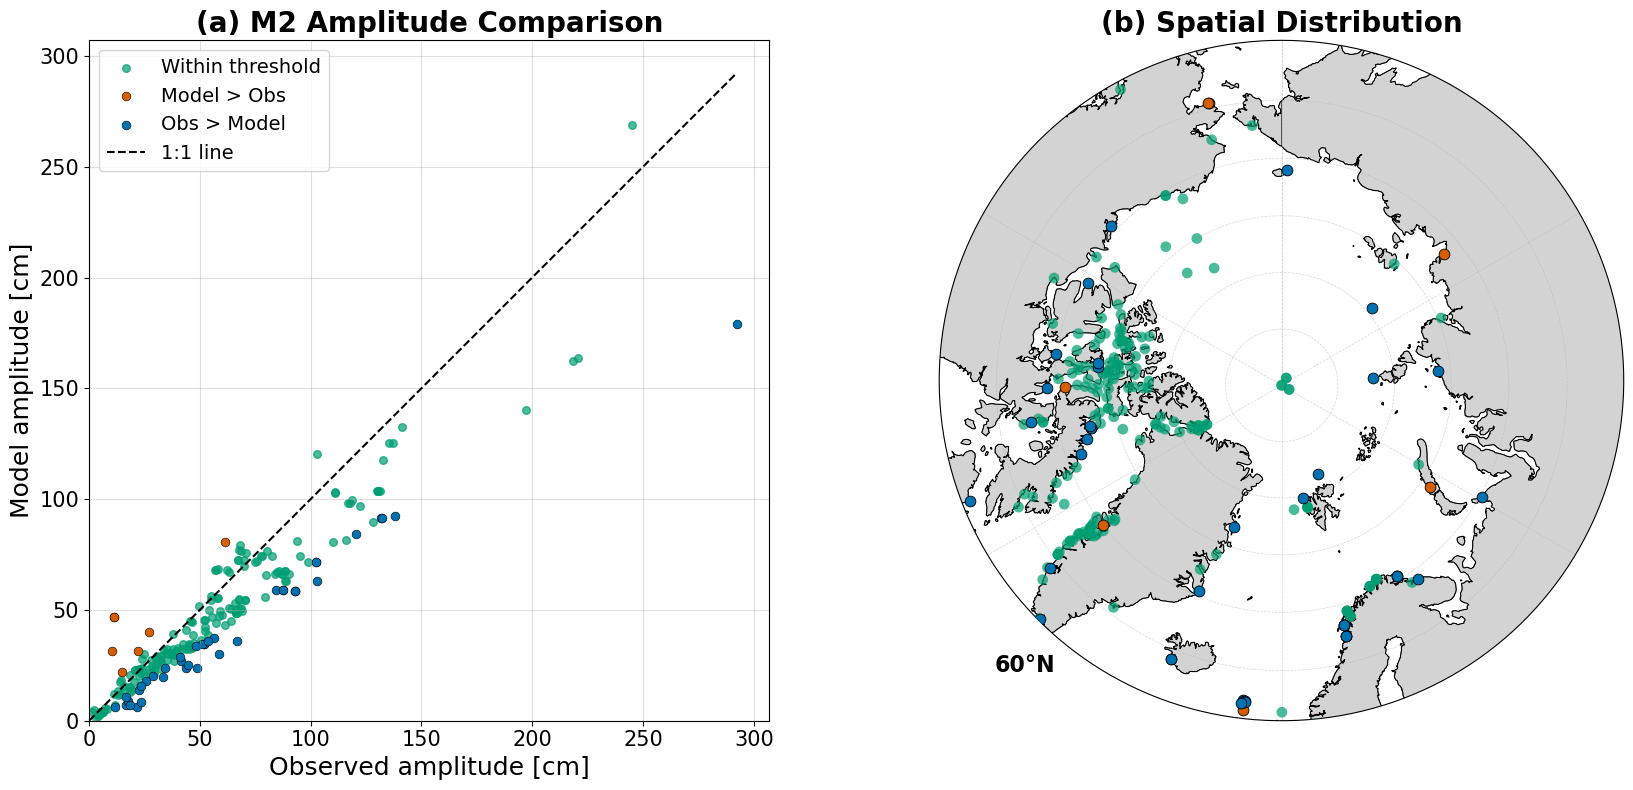

In [48]:

# ============================================================
# M2 AMPLITUDE VALIDATION — JRA55 VS ARCTIC TIDAL ATLAS
# SCATTER PLOT + ARCTIC MAP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.path as mpath

# ============================================================
# 1. DATA — ALREADY COLLOCATED AND IN CM
# ============================================================

lon_plot = np.asarray(lon_valid)
lat_plot = np.asarray(lat_valid)

amp_obs_plot = np.asarray(amp_obs_valid)
amp_mod_plot = np.asarray(amp_model_valid)

assert (
    len(lon_plot) == len(lat_plot)
    == len(amp_obs_plot) == len(amp_mod_plot)
), "Station arrays have different lengths."

# ============================================================
# 2. AMPLITUDE ERRORS AND CLASSIFICATION
# ============================================================

diff_amp = amp_mod_plot - amp_obs_plot

# Hybrid threshold: 5 cm absolute or 30% relative
threshold = np.maximum(5.0, 0.3 * amp_obs_plot)

within_threshold = np.abs(diff_amp) <= threshold
outliers_above = diff_amp > threshold
outliers_below = diff_amp < -threshold

print(f"Total valid comparison points: {len(diff_amp)}")
print(f"Within threshold: {within_threshold.sum()}")
print(f"Model > Obs: {outliers_above.sum()}")
print(f"Obs > Model: {outliers_below.sum()}")
print(f"Total outliers: {(~within_threshold).sum()}")

print("\nError statistics [cm]:")
print(f"Mean bias: {np.mean(diff_amp):.2f}")
print(f"MAE: {np.mean(np.abs(diff_amp)):.2f}")
print(f"RMSE: {np.sqrt(np.mean(diff_amp**2)):.2f}")

# ============================================================
# 3. COLORS AND FONT SIZES
# ============================================================

color_within = "#009E73"
color_above = "#D55E00"
color_below = "#0072B2"

TITLE_FONTSIZE = 20
LABEL_FONTSIZE = 18
TICK_FONTSIZE = 15
LEGEND_FONTSIZE = 14

# ============================================================
# 4. CREATE FIGURE
# ============================================================

fig = plt.figure(figsize=(18, 8))

# ============================================================
# 5. LEFT PANEL — AMPLITUDE SCATTER PLOT
# ============================================================

ax1 = fig.add_subplot(1, 2, 1)

ax1.scatter(
    amp_obs_plot[within_threshold],
    amp_mod_plot[within_threshold],
    s=30,
    color=color_within,
    alpha=0.7,
    label="Within threshold"
)

ax1.scatter(
    amp_obs_plot[outliers_above],
    amp_mod_plot[outliers_above],
    s=40,
    color=color_above,
    edgecolor="black",
    linewidth=0.4,
    label="Model > Obs"
)

ax1.scatter(
    amp_obs_plot[outliers_below],
    amp_mod_plot[outliers_below],
    s=40,
    color=color_below,
    edgecolor="black",
    linewidth=0.4,
    label="Obs > Model"
)

# 1:1 line
mx = max(
    np.nanmax(amp_obs_plot),
    np.nanmax(amp_mod_plot)
)

ax1.plot(
    [0, mx], [0, mx],
    "k--",
    linewidth=1.5,
    label="1:1 line"
)

ax1.set_xlim(0, mx * 1.05)
ax1.set_ylim(0, mx * 1.05)
ax1.set_aspect("equal", adjustable="box")

ax1.set_xlabel(
    "Observed amplitude [cm]",
    fontsize=LABEL_FONTSIZE
)

ax1.set_ylabel(
    "Model amplitude [cm]",
    fontsize=LABEL_FONTSIZE
)

ax1.set_title(
    "(a) M2 Amplitude Comparison",
    fontsize=TITLE_FONTSIZE,
    fontweight="bold"
)

ax1.tick_params(
    axis="both",
    labelsize=TICK_FONTSIZE
)

ax1.legend(fontsize=LEGEND_FONTSIZE)
ax1.grid(alpha=0.4)

# ============================================================
# 6. RIGHT PANEL — ARCTIC MAP
# ============================================================

ax2 = fig.add_subplot(
    1, 2, 2,
    projection=ccrs.NorthPolarStereo()
)

ax2.set_extent(
    [-180, 180, 60, 90],
    crs=ccrs.PlateCarree()
)

ax2.add_feature(
    cfeature.OCEAN,
    facecolor="white",
    zorder=0
)

ax2.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.3,
    zorder=1
)

ax2.coastlines(
    linewidth=0.8,
    zorder=2
)

# ============================================================
# 7. CIRCULAR ARCTIC BOUNDARY
# ============================================================

theta = np.linspace(0, 2 * np.pi, 200)

verts = np.vstack([
    np.sin(theta),
    np.cos(theta)
]).T

circle = mpath.Path(
    verts * 0.5 + [0.5, 0.5]
)

ax2.set_boundary(
    circle,
    transform=ax2.transAxes
)

# ============================================================
# 8. PLOT STATION CLASSIFICATIONS
# ============================================================

pc = ccrs.PlateCarree()

ax2.scatter(
    lon_plot[within_threshold],
    lat_plot[within_threshold],
    s=60,
    color=color_within,
    alpha=0.7,
    edgecolor="none",
    transform=pc,
    zorder=3
)

ax2.scatter(
    lon_plot[outliers_above],
    lat_plot[outliers_above],
    s=60,
    color=color_above,
    edgecolor="black",
    linewidth=0.6,
    transform=pc,
    zorder=5
)

ax2.scatter(
    lon_plot[outliers_below],
    lat_plot[outliers_below],
    s=60,
    color=color_below,
    edgecolor="black",
    linewidth=0.6,
    transform=pc,
    zorder=6
)

ax2.gridlines(
    draw_labels=False,
    linewidth=0.5,
    linestyle="--",
    alpha=0.5
)

ax2.set_title(
    "(b) Spatial Distribution",
    fontsize=TITLE_FONTSIZE,
    fontweight="bold"
)

# 60°N label
ax2.text(
    -45, 55,
    "60°N",
    fontsize=16,
    fontweight="bold",
    transform=pc,
    zorder=10
)

# ============================================================
# 9. SAVE AND SHOW
# ============================================================

plt.tight_layout()

plt.savefig(
    "M2_amp_comparison_JRA55.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [49]:

# ============================================================
# M2 PHASE — JRA55 AND ARCTIC TIDAL ATLAS
# COLLOCATION AT THE SAME 228 STATIONS
# ============================================================

# ============================================================
# 1. MODEL PHASES
# ============================================================

phase_model_values = np.asarray(phase_M2).squeeze() % 360

print("Model phase shape:", phase_model_values.shape)
print("Mesh nodes:", len(mesh.x2))

assert len(phase_model_values) == len(mesh.x2)

# ============================================================
# 2. MATCH MODEL PHASES TO ATLAS STATIONS
# ============================================================

# Use the same station selection as for amplitudes
phase_obs_valid = np.asarray(phase_obs)[on_grid] % 360
phase_model_valid = phase_model_values[idx[on_grid]]

lon_phase = np.asarray(lon_obs)[on_grid]
lat_phase = np.asarray(lat_obs)[on_grid]

# Keep finite values
valid_phase = (
    np.isfinite(phase_obs_valid) &
    np.isfinite(phase_model_valid)
)

phase_obs_valid = phase_obs_valid[valid_phase]
phase_model_valid = phase_model_valid[valid_phase]

lon_phase = lon_phase[valid_phase]
lat_phase = lat_phase[valid_phase]

# ============================================================
# 3. CIRCULAR PHASE DIFFERENCES
# ============================================================

signed_phase_diff = (
    phase_model_valid - phase_obs_valid + 180
) % 360 - 180

phase_diff = np.abs(signed_phase_diff)

phase_threshold = 30.0

within_threshold = phase_diff <= phase_threshold
outliers_above = signed_phase_diff > phase_threshold
outliers_below = signed_phase_diff < -phase_threshold

# ============================================================
# 4. STATISTICS
# ============================================================

print("Total stations:", len(phase_diff))
print("Within threshold:", within_threshold.sum())
print("Positive phase difference:", outliers_above.sum())
print("Negative phase difference:", outliers_below.sum())

print("\nMedian absolute phase difference:",
      np.median(phase_diff))

print("Mean absolute phase difference:",
      np.mean(phase_diff))


Model phase shape: (638387,)
Mesh nodes: 638387
Total stations: 228
Within threshold: 187
Positive phase difference: 5
Negative phase difference: 36

Median absolute phase difference: 16.1247644114231
Mean absolute phase difference: 21.546324362509516


Total valid comparison points: 228
Within threshold: 187
Positive phase difference: 5
Negative phase difference: 36
Total outliers: 41

Phase error statistics [degrees]:
Mean signed difference: -14.69
Median absolute difference: 16.12
MAE: 21.55
RMSE: 28.00


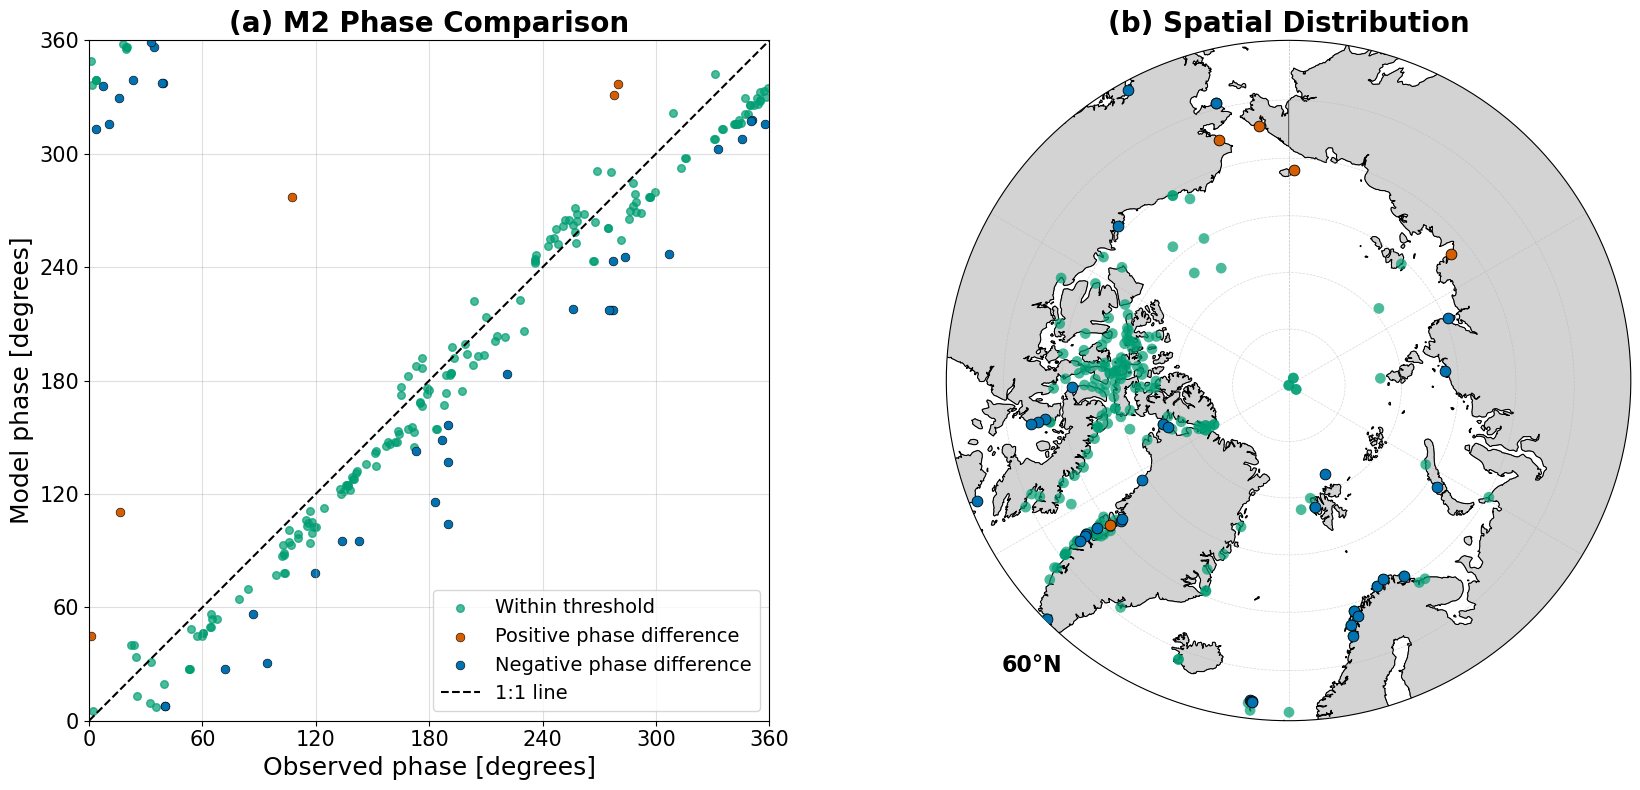

In [51]:

# ============================================================
# M2 PHASE VALIDATION — JRA55 VS ARCTIC TIDAL ATLAS
# SCATTER PLOT + ARCTIC MAP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.path as mpath

# ============================================================
# 1. DATA — ALREADY COLLOCATED
# ============================================================

lon_plot = np.asarray(lon_phase)
lat_plot = np.asarray(lat_phase)

phase_obs_plot = np.asarray(phase_obs_valid) % 360
phase_mod_plot = np.asarray(phase_model_valid) % 360

assert (
    len(lon_plot) == len(lat_plot)
    == len(phase_obs_plot) == len(phase_mod_plot)
), "Station arrays have different lengths."

# ============================================================
# 2. CIRCULAR PHASE ERRORS AND CLASSIFICATION
# ============================================================

signed_phase_diff = (
    phase_mod_plot - phase_obs_plot + 180
) % 360 - 180

phase_diff = np.abs(signed_phase_diff)

# Phase agreement threshold: ±30 degrees
phase_threshold = 30.0

within_threshold = phase_diff <= phase_threshold
outliers_above = signed_phase_diff > phase_threshold
outliers_below = signed_phase_diff < -phase_threshold

print(f"Total valid comparison points: {len(phase_diff)}")
print(f"Within threshold: {within_threshold.sum()}")
print(f"Positive phase difference: {outliers_above.sum()}")
print(f"Negative phase difference: {outliers_below.sum()}")
print(f"Total outliers: {(~within_threshold).sum()}")

print("\nPhase error statistics [degrees]:")
print(f"Mean signed difference: {np.mean(signed_phase_diff):.2f}")
print(f"Median absolute difference: {np.median(phase_diff):.2f}")
print(f"MAE: {np.mean(phase_diff):.2f}")
print(f"RMSE: {np.sqrt(np.mean(phase_diff**2)):.2f}")

# ============================================================
# 3. COLORS AND FONT SIZES
# ============================================================

color_within = "#009E73"
color_above = "#D55E00"
color_below = "#0072B2"

TITLE_FONTSIZE = 20
LABEL_FONTSIZE = 18
TICK_FONTSIZE = 15
LEGEND_FONTSIZE = 14

# ============================================================
# 4. CREATE FIGURE
# ============================================================

fig = plt.figure(figsize=(18, 8))

# ============================================================
# 5. LEFT PANEL — PHASE SCATTER PLOT
# ============================================================

ax1 = fig.add_subplot(1, 2, 1)

ax1.scatter(
    phase_obs_plot[within_threshold],
    phase_mod_plot[within_threshold],
    s=30,
    color=color_within,
    alpha=0.7,
    label="Within threshold"
)

ax1.scatter(
    phase_obs_plot[outliers_above],
    phase_mod_plot[outliers_above],
    s=40,
    color=color_above,
    edgecolor="black",
    linewidth=0.4,
    label="Positive phase difference"
)

ax1.scatter(
    phase_obs_plot[outliers_below],
    phase_mod_plot[outliers_below],
    s=40,
    color=color_below,
    edgecolor="black",
    linewidth=0.4,
    label="Negative phase difference"
)

# 1:1 line
ax1.plot(
    [0, 360],
    [0, 360],
    "k--",
    linewidth=1.5,
    label="1:1 line"
)

ax1.set_xlim(0, 360)
ax1.set_ylim(0, 360)
ax1.set_aspect("equal", adjustable="box")

ax1.set_xlabel(
    "Observed phase [degrees]",
    fontsize=LABEL_FONTSIZE
)

ax1.set_ylabel(
    "Model phase [degrees]",
    fontsize=LABEL_FONTSIZE
)

ax1.set_title(
    "(a) M2 Phase Comparison",
    fontsize=TITLE_FONTSIZE,
    fontweight="bold"
)

ax1.set_xticks(np.arange(0, 361, 60))
ax1.set_yticks(np.arange(0, 361, 60))

ax1.tick_params(
    axis="both",
    labelsize=TICK_FONTSIZE
)

ax1.legend(fontsize=LEGEND_FONTSIZE)
ax1.grid(alpha=0.4)

# ============================================================
# 6. RIGHT PANEL — ARCTIC MAP
# ============================================================

ax2 = fig.add_subplot(
    1, 2, 2,
    projection=ccrs.NorthPolarStereo()
)

ax2.set_extent(
    [-180, 180, 60, 90],
    crs=ccrs.PlateCarree()
)

ax2.add_feature(
    cfeature.OCEAN,
    facecolor="white",
    zorder=0
)

ax2.add_feature(
    cfeature.LAND,
    facecolor="lightgray",
    edgecolor="black",
    linewidth=0.3,
    zorder=1
)

ax2.coastlines(
    linewidth=0.8,
    zorder=2
)

# ============================================================
# 7. CIRCULAR ARCTIC BOUNDARY
# ============================================================

theta = np.linspace(0, 2 * np.pi, 200)

verts = np.vstack([
    np.sin(theta),
    np.cos(theta)
]).T

circle = mpath.Path(
    verts * 0.5 + [0.5, 0.5]
)

ax2.set_boundary(
    circle,
    transform=ax2.transAxes
)

# ============================================================
# 8. PLOT STATION CLASSIFICATIONS
# ============================================================

pc = ccrs.PlateCarree()

ax2.scatter(
    lon_plot[within_threshold],
    lat_plot[within_threshold],
    s=60,
    color=color_within,
    alpha=0.7,
    edgecolor="none",
    transform=pc,
    zorder=3
)

ax2.scatter(
    lon_plot[outliers_above],
    lat_plot[outliers_above],
    s=60,
    color=color_above,
    edgecolor="black",
    linewidth=0.6,
    transform=pc,
    zorder=5
)

ax2.scatter(
    lon_plot[outliers_below],
    lat_plot[outliers_below],
    s=60,
    color=color_below,
    edgecolor="black",
    linewidth=0.6,
    transform=pc,
    zorder=6
)

ax2.gridlines(
    draw_labels=False,
    linewidth=0.5,
    linestyle="--",
    alpha=0.5
)

ax2.set_title(
    "(b) Spatial Distribution",
    fontsize=TITLE_FONTSIZE,
    fontweight="bold"
)

# 60°N label
ax2.text(
    -45, 55,
    "60°N",
    fontsize=16,
    fontweight="bold",
    transform=pc,
    zorder=10
)

# ============================================================
# 9. SAVE AND SHOW
# ============================================================

plt.tight_layout()

plt.savefig(
    "M2_phase_comparison_JRA55_preliminary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Amplitude points: 228
Phase points: 228
Amplitude within threshold: 181
Amplitude model > obs: 7
Amplitude obs > model: 40
Amplitude total outliers: 47
Phase within threshold: 187
Phase model larger: 5
Phase model smaller: 36
Phase total outliers: 41


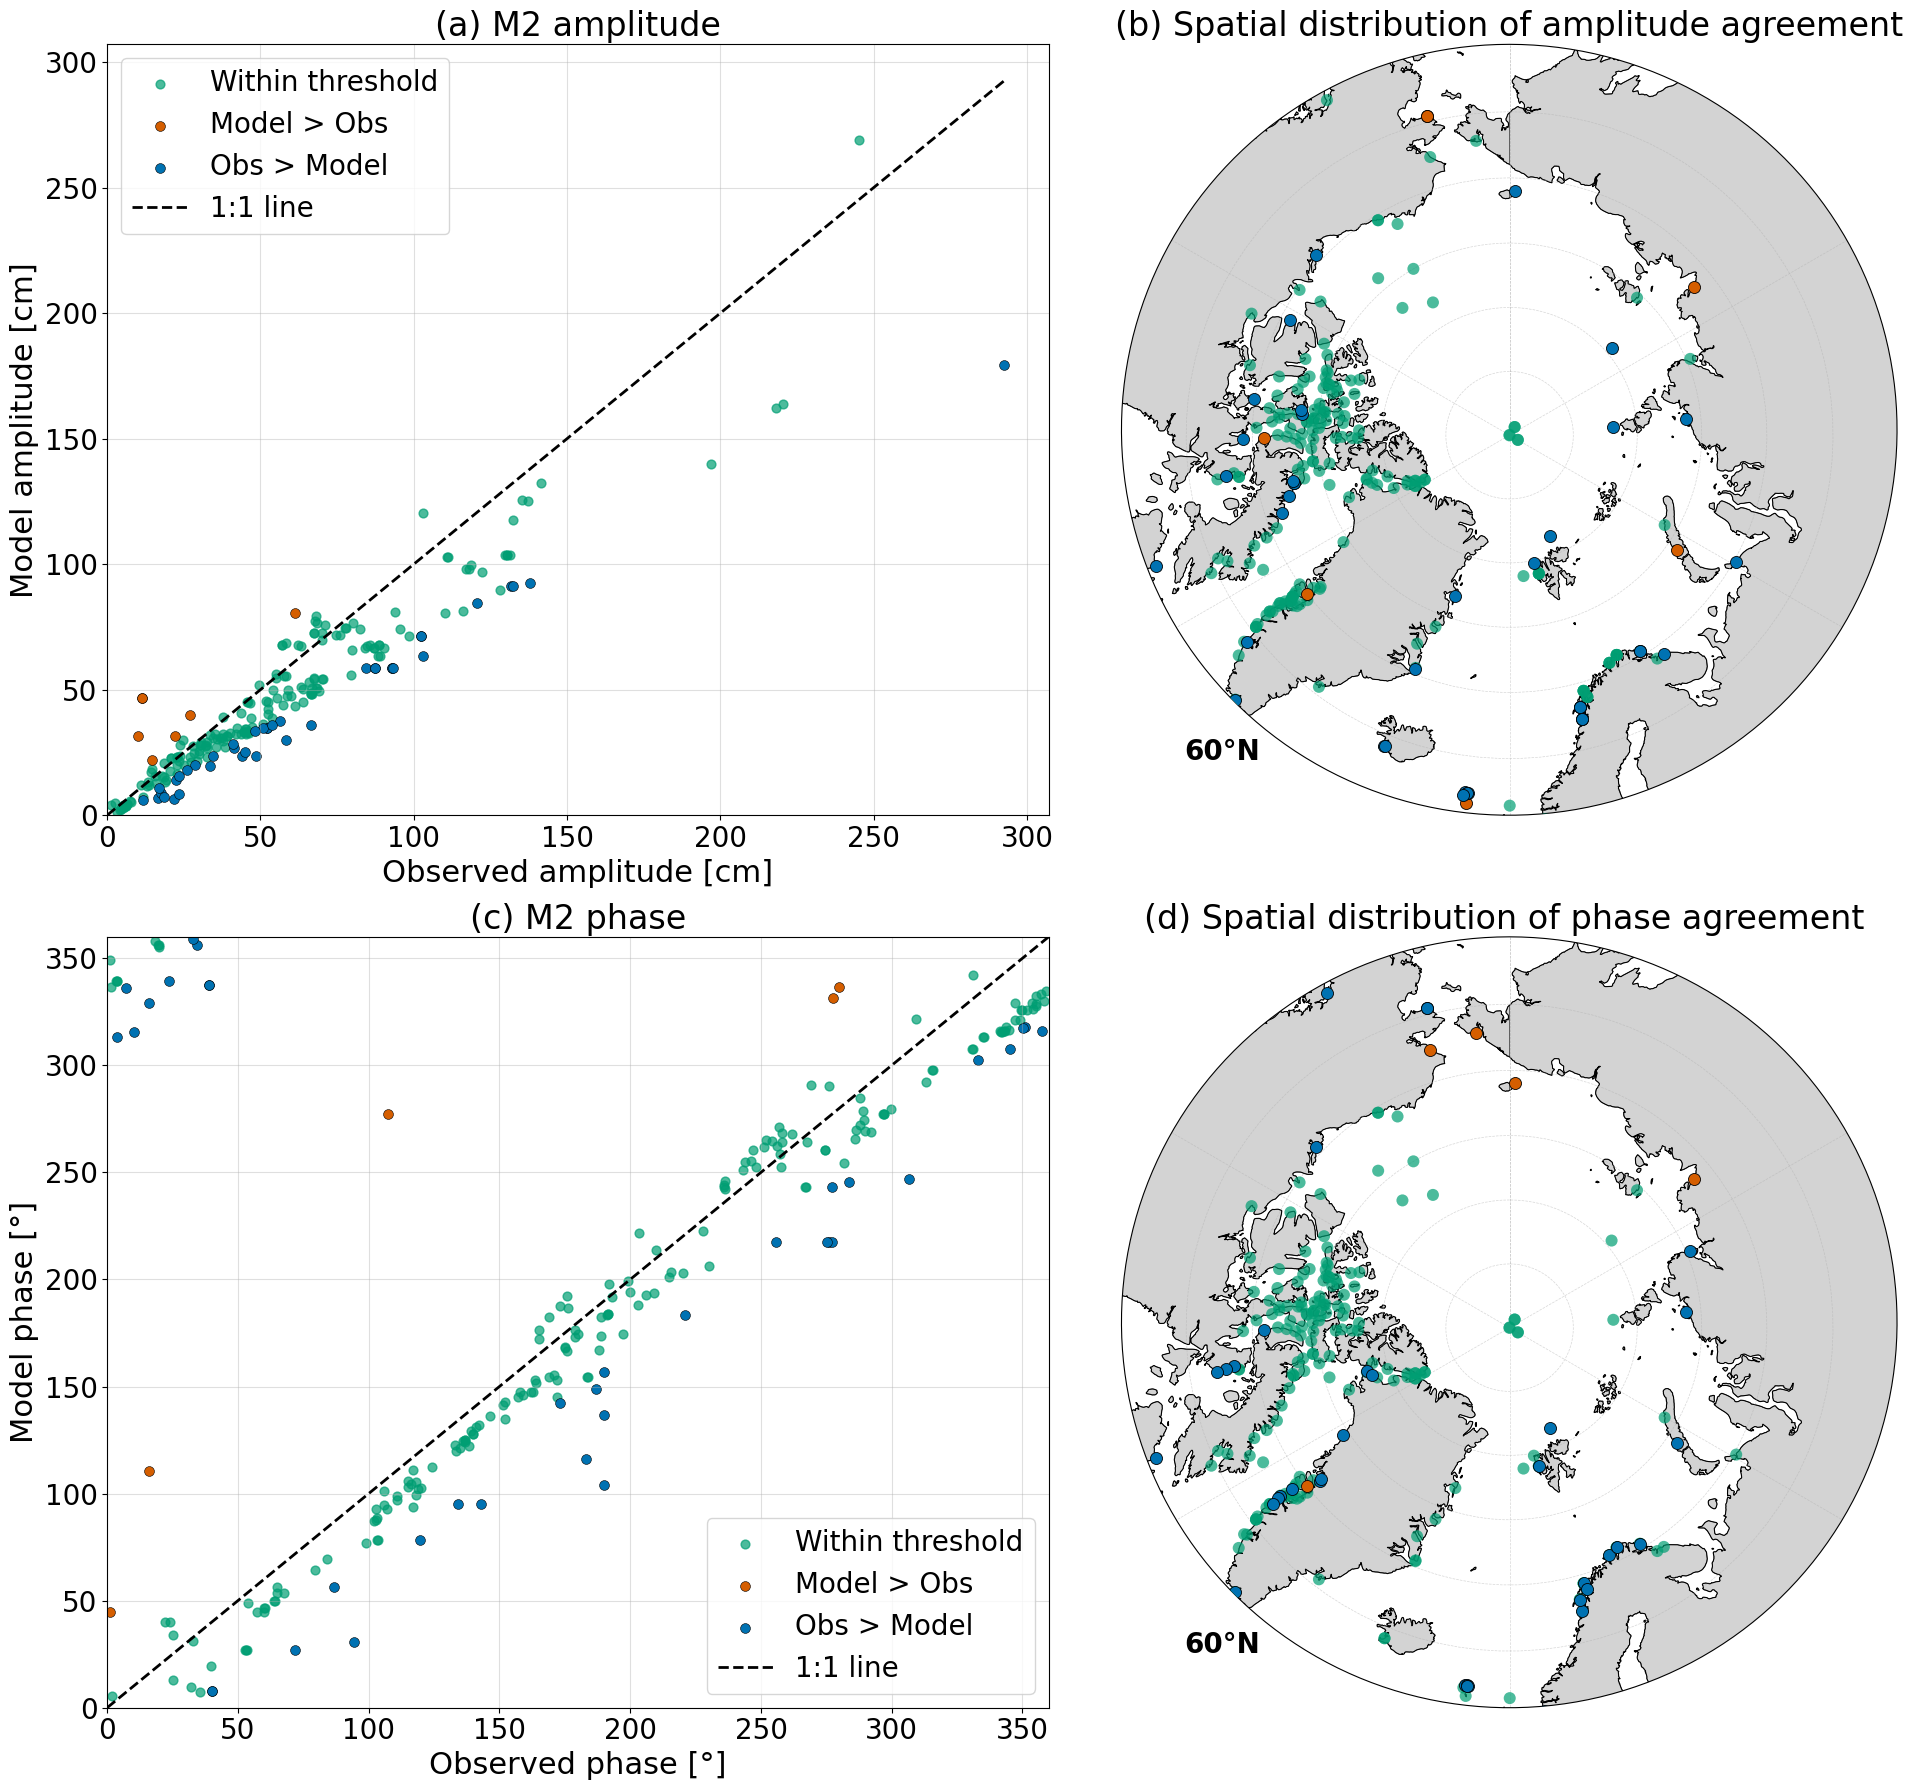

In [61]:

# ============================================================
# M2 VALIDATION — JRA55 VS ARCTIC TIDAL ATLAS
# ORIGINAL 2 × 2 PLOTTING STYLE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.path as mpath

# ============================================================
# Helper: circular phase difference
# ============================================================

def phase_diff_deg(model, obs):
    return (model - obs + 180) % 360 - 180


# ============================================================
# Font sizes — original style
# ============================================================

TITLE_FONTSIZE = 24
LABEL_FONTSIZE = 22
TICK_FONTSIZE = 20
LEGEND_FONTSIZE = 20
MAP_TEXT_FONTSIZE = 20


# ============================================================
# Data — already collocated JRA55 M2 results
# ============================================================

# Amplitude data (already in cm)
lon_amp = np.asarray(lon_valid)
lat_amp = np.asarray(lat_valid)

amp_obs_plot = np.asarray(amp_obs_valid)
model_cm = np.asarray(amp_model_valid)

# Phase data (degrees)
lon_pha = np.asarray(lon_phase)
lat_pha = np.asarray(lat_phase)

phase_obs_plot = np.asarray(phase_obs_valid) % 360
phase_model_plot = np.asarray(phase_model_valid) % 360

assert (
    len(lon_amp) == len(lat_amp)
    == len(amp_obs_plot) == len(model_cm)
), "Amplitude arrays have different lengths."

assert (
    len(lon_pha) == len(lat_pha)
    == len(phase_obs_plot) == len(phase_model_plot)
), "Phase arrays have different lengths."

print("Amplitude points:", len(amp_obs_plot))
print("Phase points:", len(phase_obs_plot))


# ============================================================
# Amplitude outliers
# ============================================================

rel_tol = 0.3
abs_tol = 5.0  # cm

amp_diff = np.abs(model_cm - amp_obs_plot)
amp_threshold = np.maximum(abs_tol, rel_tol * amp_obs_plot)

amp_outliers = amp_diff > amp_threshold
amp_within = ~amp_outliers

amp_model_above = amp_outliers & (model_cm > amp_obs_plot)
amp_model_below = amp_outliers & (model_cm < amp_obs_plot)


# ============================================================
# Phase outliers
# ============================================================

phase_threshold = 30.0  # degrees

phase_diff = phase_diff_deg(
    phase_model_plot,
    phase_obs_plot
)

phase_outliers = np.abs(phase_diff) > phase_threshold
phase_within = ~phase_outliers

phase_model_larger = phase_outliers & (phase_diff > 0)
phase_model_smaller = phase_outliers & (phase_diff < 0)


# ============================================================
# Print statistics
# ============================================================

print("Amplitude within threshold:", np.sum(amp_within))
print("Amplitude model > obs:", np.sum(amp_model_above))
print("Amplitude obs > model:", np.sum(amp_model_below))
print("Amplitude total outliers:", np.sum(amp_outliers))

print("Phase within threshold:", np.sum(phase_within))
print("Phase model larger:", np.sum(phase_model_larger))
print("Phase model smaller:", np.sum(phase_model_smaller))
print("Phase total outliers:", np.sum(phase_outliers))


# ============================================================
# Colors
# ============================================================

color_within = "#009E73"
color_above = "#D55E00"
color_below = "#0072B2"


# ============================================================
# Map helper
# ============================================================

def setup_arctic_map(ax):

    ax.set_extent(
        [-180, 180, 60, 90],
        crs=ccrs.PlateCarree()
    )

    ax.add_feature(
        cfeature.OCEAN,
        facecolor="white",
        zorder=0
    )

    ax.add_feature(
        cfeature.LAND,
        facecolor="lightgray",
        edgecolor="black",
        linewidth=0.3,
        zorder=1
    )

    ax.coastlines(
        linewidth=0.8,
        zorder=2
    )

    theta = np.linspace(0, 2 * np.pi, 200)

    circle = mpath.Path(
        np.vstack([
            np.sin(theta),
            np.cos(theta)
        ]).T * 0.5 + [0.5, 0.5]
    )

    ax.set_boundary(
        circle,
        transform=ax.transAxes
    )

    ax.gridlines(
        draw_labels=False,
        linewidth=0.5,
        linestyle="--",
        alpha=0.5
    )

    ax.text(
        -45,
        55,
        "60°N",
        fontsize=MAP_TEXT_FONTSIZE,
        fontweight="bold",
        transform=ccrs.PlateCarree(),
        zorder=10
    )


# ============================================================
# Create figure — original dimensions
# ============================================================

fig = plt.figure(figsize=(20, 18))


# ============================================================
# (a) Amplitude scatter
# ============================================================

ax1 = fig.add_subplot(2, 2, 1)

ax1.scatter(
    amp_obs_plot[amp_within],
    model_cm[amp_within],
    s=40,
    color=color_within,
    alpha=0.7,
    label="Within threshold"
)

ax1.scatter(
    amp_obs_plot[amp_model_above],
    model_cm[amp_model_above],
    s=50,
    color=color_above,
    edgecolor="black",
    linewidth=0.4,
    label="Model > Obs"
)

ax1.scatter(
    amp_obs_plot[amp_model_below],
    model_cm[amp_model_below],
    s=50,
    color=color_below,
    edgecolor="black",
    linewidth=0.4,
    label="Obs > Model"
)

mx = max(
    np.nanmax(amp_obs_plot),
    np.nanmax(model_cm)
)

ax1.plot(
    [0, mx],
    [0, mx],
    "k--",
    linewidth=2,
    label="1:1 line"
)

ax1.set_xlim(0, mx * 1.05)
ax1.set_ylim(0, mx * 1.05)

ax1.set_xlabel(
    "Observed amplitude [cm]",
    fontsize=LABEL_FONTSIZE
)

ax1.set_ylabel(
    "Model amplitude [cm]",
    fontsize=LABEL_FONTSIZE
)

ax1.set_title(
    "(a) M2 amplitude",
    fontsize=TITLE_FONTSIZE
    #fontweight="bold"
)

ax1.tick_params(
    axis="both",
    labelsize=TICK_FONTSIZE
)

ax1.grid(alpha=0.4)

ax1.legend(
    fontsize=LEGEND_FONTSIZE,
    frameon=True
)


# ============================================================
# (b) Amplitude map
# ============================================================

ax2 = fig.add_subplot(
    2, 2, 2,
    projection=ccrs.NorthPolarStereo()
)

setup_arctic_map(ax2)

ax2.scatter(
    lon_amp[amp_within],
    lat_amp[amp_within],
    s=75,
    color=color_within,
    alpha=0.7,
    edgecolor="none",
    transform=ccrs.PlateCarree(),
    zorder=3,
    label="Within threshold"
)

ax2.scatter(
    lon_amp[amp_model_above],
    lat_amp[amp_model_above],
    s=75,
    color=color_above,
    edgecolor="black",
    linewidth=0.6,
    transform=ccrs.PlateCarree(),
    zorder=5,
    label="Model > Obs"
)

ax2.scatter(
    lon_amp[amp_model_below],
    lat_amp[amp_model_below],
    s=75,
    color=color_below,
    edgecolor="black",
    linewidth=0.6,
    transform=ccrs.PlateCarree(),
    zorder=6,
    label="Obs > Model"
)

ax2.set_title(
    "(b) Spatial distribution of amplitude agreement",
    fontsize=TITLE_FONTSIZE
    #fontweight="bold"
)


# ============================================================
# (c) Phase scatter
# ============================================================

ax3 = fig.add_subplot(2, 2, 3)

ax3.scatter(
    phase_obs_plot[phase_within],
    phase_model_plot[phase_within],
    s=40,
    color=color_within,
    alpha=0.7,
    label="Within threshold"
)

ax3.scatter(
    phase_obs_plot[phase_model_larger],
    phase_model_plot[phase_model_larger],
    s=50,
    color=color_above,
    edgecolor="black",
    linewidth=0.4,
    label="Model > Obs"
)

ax3.scatter(
    phase_obs_plot[phase_model_smaller],
    phase_model_plot[phase_model_smaller],
    s=50,
    color=color_below,
    edgecolor="black",
    linewidth=0.4,
    label="Obs > Model"
)

ax3.plot(
    [0, 360],
    [0, 360],
    "k--",
    linewidth=2,
    label="1:1 line"
)

ax3.set_xlim(0, 360)
ax3.set_ylim(0, 360)

ax3.set_xlabel(
    "Observed phase [°]",
    fontsize=LABEL_FONTSIZE
)

ax3.set_ylabel(
    "Model phase [°]",
    fontsize=LABEL_FONTSIZE
)

ax3.set_title(
    "(c) M2 phase",
    fontsize=TITLE_FONTSIZE
    #fontweight="bold"
)

ax3.tick_params(
    axis="both",
    labelsize=TICK_FONTSIZE
)

ax3.grid(alpha=0.4)

ax3.legend(
    fontsize=LEGEND_FONTSIZE,
    frameon=True
)


# ============================================================
# (d) Phase map
# ============================================================

ax4 = fig.add_subplot(
    2, 2, 4,
    projection=ccrs.NorthPolarStereo()
)

setup_arctic_map(ax4)

ax4.scatter(
    lon_pha[phase_within],
    lat_pha[phase_within],
    s=75,
    color=color_within,
    alpha=0.7,
    edgecolor="none",
    transform=ccrs.PlateCarree(),
    zorder=3,
    label="Within threshold"
)

ax4.scatter(
    lon_pha[phase_model_larger],
    lat_pha[phase_model_larger],
    s=75,
    color=color_above,
    edgecolor="black",
    linewidth=0.6,
    transform=ccrs.PlateCarree(),
    zorder=5,
    label="Model > Obs"
)

ax4.scatter(
    lon_pha[phase_model_smaller],
    lat_pha[phase_model_smaller],
    s=75,
    color=color_below,
    edgecolor="black",
    linewidth=0.6,
    transform=ccrs.PlateCarree(),
    zorder=6,
    label="Obs > Model"
)

ax4.set_title(
    "(d) Spatial distribution of phase agreement ",
    fontsize=TITLE_FONTSIZE
    #fontweight="bold"
)


# ============================================================
# Final layout — original
# ============================================================

plt.tight_layout()

plt.savefig(
    "M2_amplitude_phase_JRA55.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "M2_amplitude_phase_JRA55.pdf",
    bbox_inches="tight"
)

plt.show()
